# Deep generative integration with `ov.vi` — in memory, on disk, on the GPU

`ov.vi` is omicverse's own implementation of the scVI model family —
**SCVI**, **SCANVI** and **TOTALVI** — written in plain PyTorch with the
scvi-tools API and defaults, but **no scvi-tools / Lightning dependency**. Its
data layer feeds minibatches straight from wherever the count matrix lives:

| Input | How you get it | How minibatches are made |
|---|---|---|
| in-memory `AnnData` | `ov.read(path)` | CSR uploaded to the GPU once, rows gathered there |
| `AnnDataOOM` (disk) | `ov.read(path, storage='disk')` in CPU / mixed mode | row blocks read with anndataoom-fast's `pread` reader, block-shuffled; host memory bounded by the shuffle buffer |
| Dask-backed `AnnData` | `ov.read(path, storage='disk')` in GPU mode | Dask row blocks computed as cupy arrays and handed to torch (DLPack) |

`ov.single.batch_correction(methods='scVI' | 'scANVI' | 'totalVI')` uses
`ov.vi` under the hood (see the [zoo](zoo/index.md)); here we use the model
classes directly.

**This tutorial** — real data end to end, the NeurIPS 2021 bone-marrow
dataset (3 donors, all 27 423 cells):

1. `ov.vi.SCVI` on in-memory data: training curve, latent, MDE, denoised marker expression;
2. the same model trained **from disk** (AnnDataOOM): memory and latent quality;
3. the same model in **GPU mode** with Dask;
4. **SCANVI** label transfer to a donor whose labels are hidden;
5. multi-GPU training; 6. speed vs. scvi-tools.

Executed on one NVIDIA H100 80 GB with 20 CPU threads.

In [1]:
import omicverse as ov
import anndata as ad
import numpy as np
import pandas as pd
ov.style()

🔬 Starting plot initialization...
🧬 Detecting GPU devices…


✅ NVIDIA CUDA GPUs detected: 1
    • [CUDA 0] NVIDIA H100 80GB HBM3
      Memory: 79.1 GB | Compute: 9.0

   ____            _     _    __                  
  / __ \____ ___  (_)___| |  / /__  _____________ 
 / / / / __ `__ \/ / ___/ | / / _ \/ ___/ ___/ _ \ 
/ /_/ / / / / / / / /__ | |/ /  __/ /  (__  )  __/ 
\____/_/ /_/ /_/_/\___/ |___/\___/_/  /____/\___/                                              

🔖 Version: unknown   📚 Tutorials: https://omicverse.readthedocs.io/
✅ plot_set complete.



## 1. Data

Bone-marrow mononuclear cells of the NeurIPS 2021 multimodal integration
benchmark (Luecken *et al.*, 2021), gene expression of the CITE-seq arm: donors
`s1d3`, `s2d1`, `s3d7` profiled at three sites — one batch each — with the
authors' cell-type annotation. Raw counts are stored in `layers['counts']`; we
move them into `X` (the models read raw counts).

In [2]:
adata1 = ov.datasets.get_adata('https://figshare.com/ndownloader/files/41932005', filename='neurips2021_s1d3.h5ad')
adata2 = ov.datasets.get_adata('https://figshare.com/ndownloader/files/41932008', filename='neurips2021_s2d1.h5ad')
adata3 = ov.datasets.get_adata('https://figshare.com/ndownloader/files/41932011', filename='neurips2021_s3d7.h5ad')

⚠️ File ./data/neurips2021_s1d3.h5ad already exists
 Loading data from ./data/neurips2021_s1d3.h5ad


✅ Successfully loaded: 5935 cells × 13953 genes
⚠️ File ./data/neurips2021_s2d1.h5ad already exists
 Loading data from ./data/neurips2021_s2d1.h5ad


✅ Successfully loaded: 10258 cells × 13953 genes
⚠️ File ./data/neurips2021_s3d7.h5ad already exists
 Loading data from ./data/neurips2021_s3d7.h5ad


✅ Successfully loaded: 11230 cells × 13953 genes


In [3]:
adata = ad.concat([adata1, adata2, adata3], merge='same')
adata.X = adata.layers['counts']
del adata.layers['counts']
adata.obs['batch'] = adata.obs['batch'].astype('category')
adata

AnnData object with n_obs × n_vars = 27423 × 13953
    obs: 'GEX_n_genes_by_counts', 'GEX_pct_counts_mt', 'GEX_size_factors', 'GEX_phase', 'ADT_n_antibodies_by_counts', 'ADT_total_counts', 'ADT_iso_count', 'cell_type', 'batch', 'ADT_pseudotime_order', 'GEX_pseudotime_order', 'Samplename', 'Site', 'DonorNumber', 'Modality', 'VendorLot', 'DonorID', 'DonorAge', 'DonorBMI', 'DonorBloodType', 'DonorRace', 'Ethnicity', 'DonorGender', 'QCMeds', 'DonorSmoker', 'is_train'
    var: 'feature_types', 'gene_id'
    obsm: 'ADT_X_pca', 'ADT_X_umap', 'ADT_isotype_controls', 'GEX_X_pca', 'GEX_X_umap'
    layers: None (.X)

In [4]:
pd.crosstab(adata.obs['cell_type'], adata.obs['batch']).sort_values('s1d3', ascending=False).head(10)

batch                 s1d3  s2d1  s3d7
cell_type                             
Reticulocyte           929   270   291
CD8+ T naive           878   312   116
CD4+ T naive           833   883   219
CD4+ T activated       547   690   380
CD14+ Mono             309  2958  6056
NK                     271   282  1242
Naive CD20+ B IGKC+    265   585    88
CD8+ T CD57+ CD45RA+   251    30     0
Transitional B         250    43   119
Erythroblast           228  1202   307

The donors differ strongly in composition (e.g. `s3d7` is dominated by CD14⁺
monocytes, `s1d3` by T cells and reticulocytes) — the situation where
integration must remove the technical donor/site effect without forcing
different cell types together.

We also save the raw-count matrix as an `.h5ad` now: it is the input of the
disk and GPU sections.

In [5]:
h5ad_path = 'neurips2021_bmmc_counts.h5ad'
adata.write_h5ad(h5ad_path)

## 2. `ov.vi.SCVI` on in-memory data

QC (the cells are already filtered by the authors, so the thresholds are
loose) and 2 000 highly variable genes. `ov.pp.preprocess` keeps the raw
counts in `layers['counts']` and flags the HVGs in
`var['highly_variable_features']` — we do **not** subset the AnnData: the model
selects the training genes itself (`genes=`), which also works for disk data.

In [6]:
adata = ov.pp.qc(adata, tresh={'mito_perc': 0.2, 'nUMIs': 500, 'detected_genes': 250}, doublets=False)
adata = ov.pp.preprocess(adata, mode='shiftlog|pearson', n_HVGs=2000)
adata

🖥️ Using CPU mode for QC...
   Auto-detected mitochondrial prefix: 'MT-'

📊 Step 1: Calculating QC Metrics

   ✓ Gene Family Detection:
   ┌──────────────────────────────┬────────────────────┬────────────────────┐
   │ Gene Family                  │ Genes Found        │ Detection Method   │
   ├──────────────────────────────┼────────────────────┼────────────────────┤
   │ Mitochondrial                │ 13                 │ Auto (MT-)         │
   ├──────────────────────────────┼────────────────────┼────────────────────┤
   │ Ribosomal                    │ 94                 │ Auto (RPS/RPL)     │
   ├──────────────────────────────┼────────────────────┼────────────────────┤
   │ Hemoglobin                   │ 11                 │ Auto (regex)       │
   └──────────────────────────────┴────────────────────┴────────────────────┘



   ✓ QC Metrics Summary:
   ┌─────────────────────────┬────────────────────┬─────────────────────────┐
   │ Metric                  │ Mean               │ Range (Min - Max)       │
   ├─────────────────────────┼────────────────────┼─────────────────────────┤
   │ nUMIs                   │ 5197               │ 742 - 32877             │
   ├─────────────────────────┼────────────────────┼─────────────────────────┤
   │ Detected Genes          │ 1339               │ 103 - 5543              │
   ├─────────────────────────┼────────────────────┼─────────────────────────┤
   │ Mitochondrial %         │ 6.6%               │ 0.0% - 23.0%            │
   ├─────────────────────────┼────────────────────┼─────────────────────────┤
   │ Ribosomal %             │ 24.6%              │ 0.1% - 69.4%            │
   ├─────────────────────────┼────────────────────┼─────────────────────────┤
   │ Hemoglobin %            │ 9.7%               │ 0.0% - 96.1%            │
   └─────────────────────────┴────────

   ✓ Final filtering: 0 cells, 0 genes removed

📊 Step 4: Doublet detection disabled

╭─ SUMMARY: qc ──────────────────────────────────────────────────────╮
│  Duration: 1.1847s                                                 │
│  Shape:    27,423 x 13,953 (Unchanged)                             │
│                                                                    │
│  CHANGES DETECTED                                                  │
│  ────────────────                                                  │
│  ● OBS    │ ✚ cell_complexity (float)                              │
│           │ ✚ detected_genes (int)                                 │
│           │ ✚ hb_perc (float)                                      │
│           │ ✚ mito_perc (float)                                    │
│           │ ✚ nUMIs (float)                                        │
│           │ ✚ n_counts (float)                                     │
│           │ ✚ n_genes (int)                                 

Begin size normalization: shiftlog and HVGs selection pearson

🔍 Count Normalization:
   Target sum: 500000.0
   Exclude highly expressed: True
   Max fraction threshold: 0.2


   ⚠️ Excluding 9 highly-expressed genes from normalization computation
   Excluded genes: ['IGKC', 'HBB', 'MALAT1', 'IGHA1', 'IGHM', 'HBA2', 'IGLC1', 'IGLC2', 'IGLC3']

✅ Count Normalization Completed Successfully!
   ✓ Processed: 26,997 cells × 13,953 genes
   ✓ Runtime: 0.36s

🔍 Highly Variable Genes Selection (Experimental):
   Method: pearson_residuals
   Target genes: 2,000
   Theta (overdispersion): 100



✅ Experimental HVG Selection Completed Successfully!
   ✓ Selected: 2,000 highly variable genes out of 13,953 total (14.3%)
   ✓ Results added to AnnData object:
     • 'highly_variable': Boolean vector (adata.var)
     • 'highly_variable_rank': Float vector (adata.var)
     • 'highly_variable_nbatches': Int vector (adata.var)
     • 'highly_variable_intersection': Boolean vector (adata.var)
     • 'means': Float vector (adata.var)
     • 'variances': Float vector (adata.var)
     • 'residual_variances': Float vector (adata.var)
    Time to analyze data in cpu: 2.17 seconds.
✅ Preprocessing completed successfully.
    Added:
        'highly_variable_features', boolean vector (adata.var)
        'means', float vector (adata.var)
        'variances', float vector (adata.var)
        'residual_variances', float vector (adata.var)
        'counts', raw counts layer (adata.layers)
    End of size normalization: shiftlog and HVGs selection pearson

╭─ SUMMARY: preprocess ───────────────────

AnnData object with n_obs × n_vars = 26997 × 13953
    obs: 'GEX_n_genes_by_counts', 'GEX_pct_counts_mt', 'GEX_size_factors', 'GEX_phase', 'ADT_n_antibodies_by_counts', 'ADT_total_counts', 'ADT_iso_count', 'cell_type', 'batch', 'ADT_pseudotime_order', 'GEX_pseudotime_order', 'Samplename', 'Site', 'DonorNumber', 'Modality', 'VendorLot', 'DonorID', 'DonorAge', 'DonorBMI', 'DonorBloodType', 'DonorRace', 'Ethnicity', 'DonorGender', 'QCMeds', 'DonorSmoker', 'is_train', 'nUMIs', 'mito_perc', 'ribo_perc', 'hb_perc', 'detected_genes', 'cell_complexity', 'n_counts', 'total_counts', 'n_genes', 'n_genes_by_counts', 'pct_counts_mt', 'pct_counts_ribo', 'pct_counts_hb', 'passing_mt', 'passing_nUMIs', 'passing_ngenes'
    var: 'feature_types', 'gene_id', 'mt', 'ribo', 'hb', 'n_cells', 'percent_cells', 'robust', 'highly_variable_features', 'means', 'variances', 'residual_variances', 'highly_variable_rank', 'highly_variable'
    uns: 'status', 'status_args', 'REFERENCE_MANU', '_ov_provenance', 'history

Configuration goes to the constructor (no `setup_anndata`): the counts layer,
the batch column and the genes are stored in `model.registry` and re-applied to
any AnnData given later (query data, `load`). Two hidden layers and a
30-dimensional latent, as in the scVI atlas-integration benchmarks.

In [7]:
model = ov.vi.SCVI(adata, layer='counts', batch_key='batch', genes='highly_variable_features',
                    n_layers=2, n_latent=30)
model

SCVI(n_obs=26997, n_vars=2000, n_batch=3, n_labels=1, layer='counts', trained=False)

`train()` uses the GPU when one is available. `max_epochs` defaults to the
scvi-tools heuristic `min(round(20000 / n_cells * 400), 400)` (296 epochs here);
we record the validation ELBO every 10 epochs. `ov.vi.MemoryMonitor` reports
wall time, host RSS and GPU memory of the block.

In [8]:
with ov.vi.MemoryMonitor() as mon_mem:
    model.train(check_val_every_n_epoch=10)
mon_mem

Training:   0%|          | 0/296 [00:00<?, ?epoch/s]

MemoryMonitor(wall 53.2 s, RSS 2.17 -> peak 2.97 GB (+0.81), GPU used peak 1.39 GB)

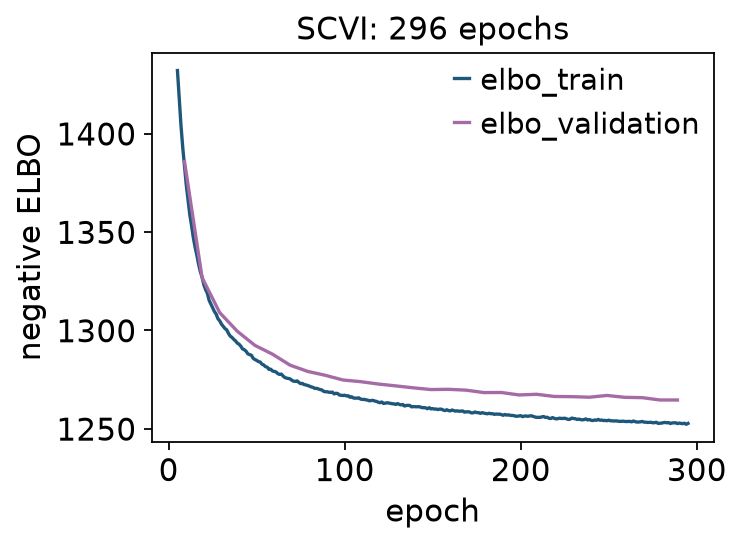

In [9]:
ov.vi.plot_history(model, skip_first=5);

Both curves drop and flatten; the validation ELBO does not turn upwards, so the
model is not overfitting. `model.history` gives the same numbers as
DataFrames, `model.history_['time']` the per-epoch wall time.

### Latent space

The posterior mean of `z` per cell, a 2-D MDE of it, and — for reference — the
uncorrected PCA of the scaled HVGs:

In [10]:
adata.obsm['X_scVI'] = model.get_latent_representation()
adata.obsm['X_mde_scVI'] = ov.vi.mde(adata.obsm['X_scVI'])
ov.pp.scale(adata)
ov.pp.pca(adata, layer='scaled', n_pcs=30)
adata.obsm['X_mde_pca'] = ov.vi.mde(adata.obsm['X_pca'])


╭─ SUMMARY: scale ───────────────────────────────────────────────────╮
│  Duration: 0.7338s                                                 │
│  Shape:    26,997 x 13,953 (Unchanged)                             │
│                                                                    │
│  CHANGES DETECTED                                                  │
│  ────────────────                                                  │
│  ● LAYERS │ ✚ scaled (array, 26997x13953)                          │
│                                                                    │
╰────────────────────────────────────────────────────────────────────╯
computing PCA🔍
    with n_comps=30


   🖥️ Using sklearn PCA for CPU computation
   🖥️ sklearn PCA backend: CPU computation
   📊 PCA input data type: ArrayView, shape: (26997, 2000), dtype: float64


   🔧 PCA solver used: covariance_eigh
    finished✅ (3.03s)

╭─ SUMMARY: pca ─────────────────────────────────────────────────────╮
│  Duration: 3.0448s                                                 │
│  Shape:    26,997 x 13,953 (Unchanged)                             │
│                                                                    │
│  CHANGES DETECTED                                                  │
│  ────────────────                                                  │
│  ● UNS    │ ✚ pca                                                  │
│           │ └─ params: {'zero_center': True, 'use_highly_variable': Tr...│
│           │ ✚ scaled|original|cum_sum_eigenvalues                  │
│           │ ✚ scaled|original|pca_var_ratios                       │
│                                                                    │
│  ● OBSM   │ ✚ X_pca (array, 26997x30)                              │
│           │ ✚ scaled|original|X_pca (array, 26997x30)              │
│         

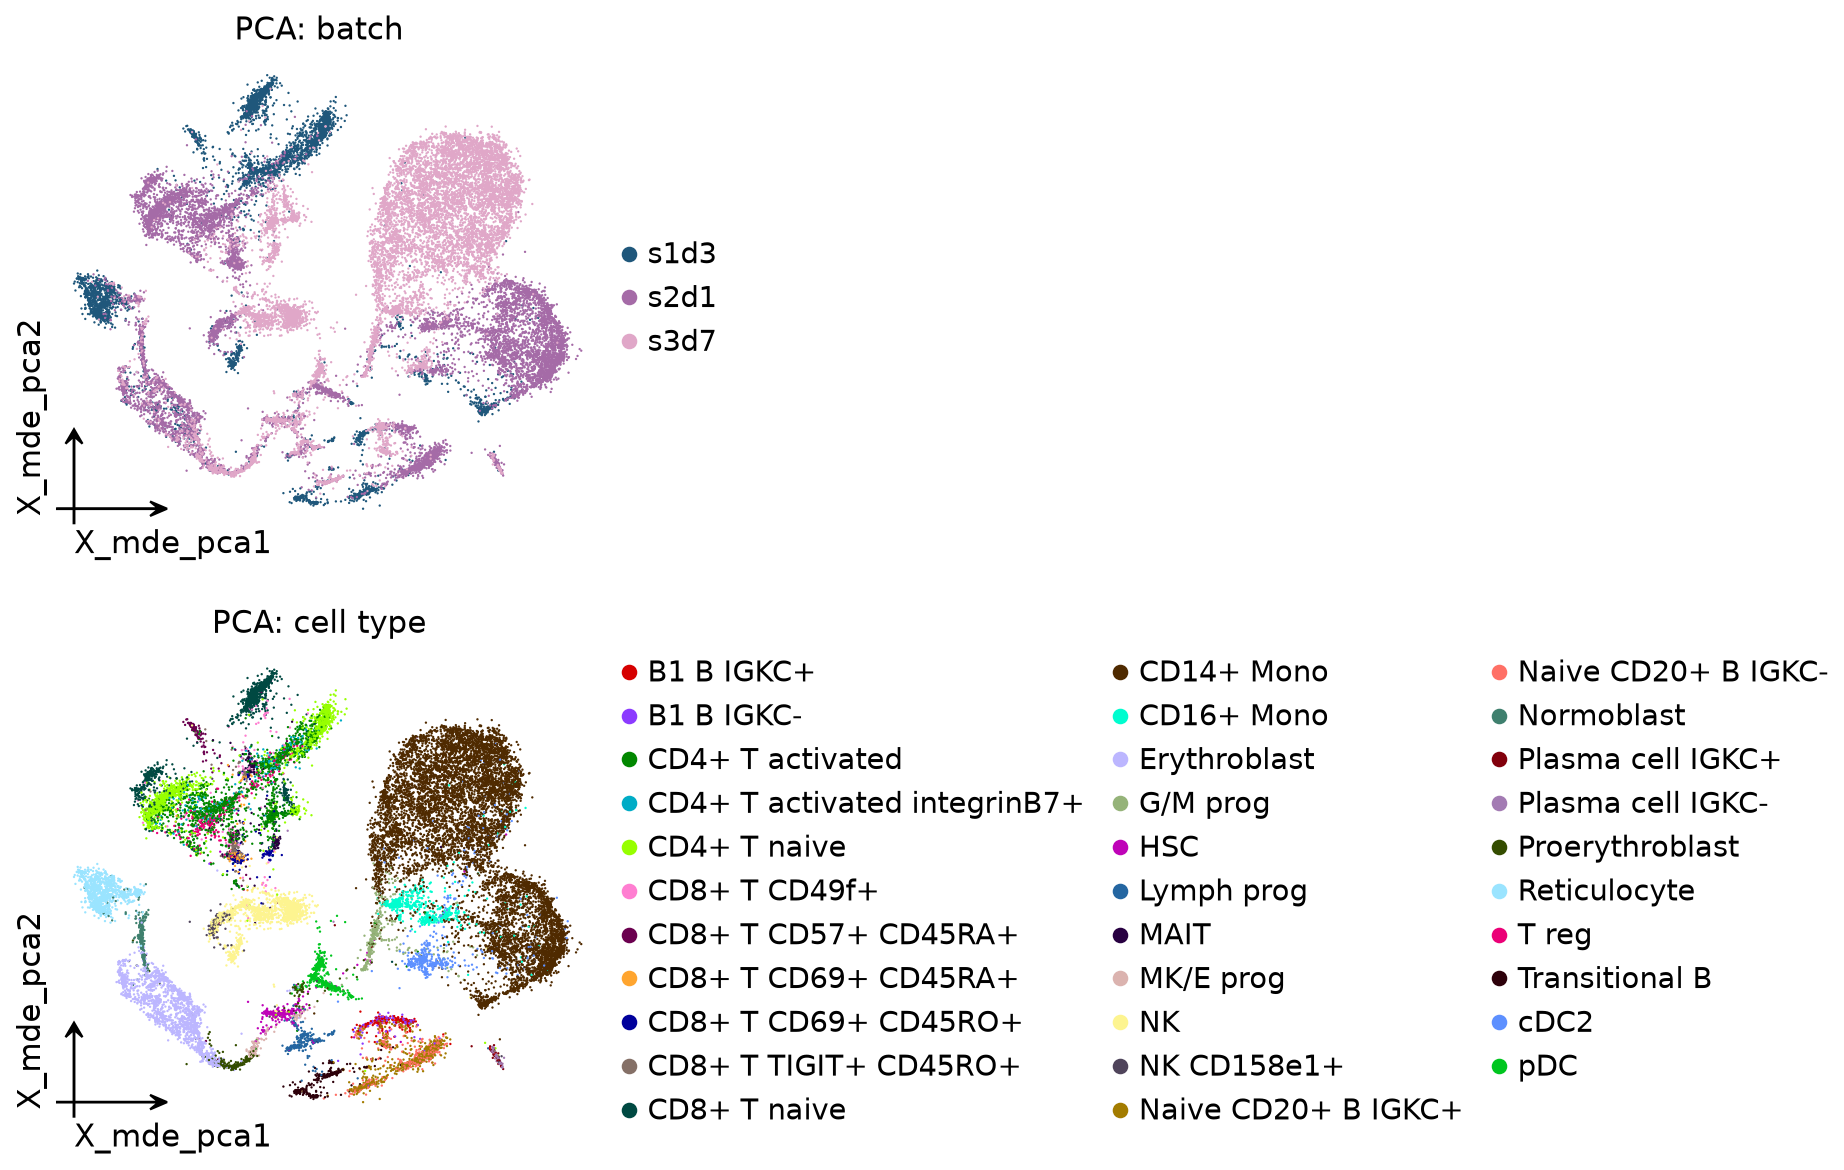

In [11]:
ov.pl.embedding(adata, basis='X_mde_pca', color=['batch', 'cell_type'],
                frameon='small', wspace=0.65, title=['PCA: batch', 'PCA: cell type'])

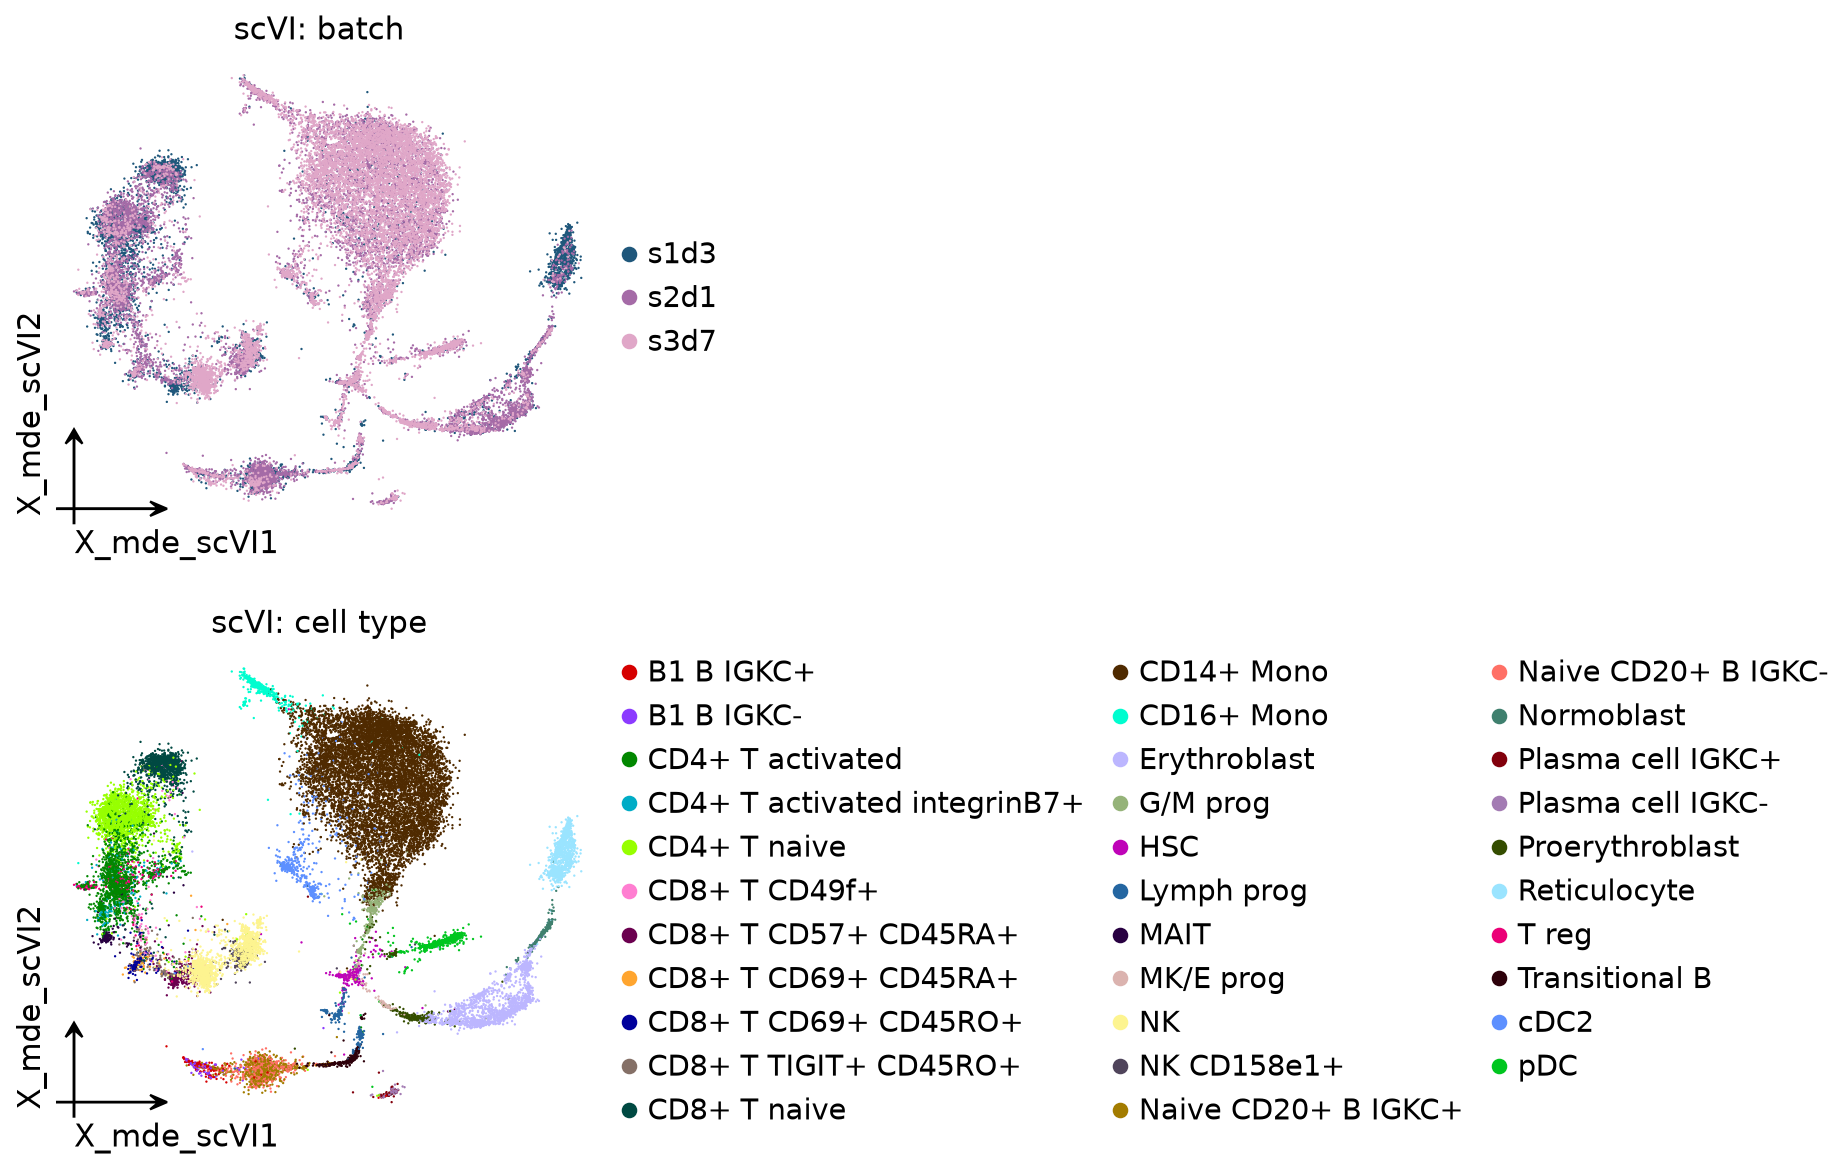

In [12]:
ov.pl.embedding(adata, basis='X_mde_scVI', color=['batch', 'cell_type'],
                frameon='small', wspace=0.65, title=['scVI: batch', 'scVI: cell type'])

In PCA space the donors form separate islands within the monocyte, T-cell and
erythroid compartments; in the scVI latent they overlap, while the lineages —
HSC → erythroid, myeloid, B and pDC branches, T / NK cells — remain distinct.

### Denoised expression

`get_normalized_expression` decodes the latent into denoised, library-size
normalised expression (here scaled to 10 000 counts per cell). Canonical
markers should light up their lineages: CD14 (monocytes), MS4A1 (B cells), CD3E
(T cells), NKG7 (NK / cytotoxic T), HBB (erythroid), LILRA4 (pDC).

In [13]:
markers = ['CD14', 'MS4A1', 'CD3E', 'NKG7', 'HBB', 'LILRA4']
expr = model.get_normalized_expression(gene_list=markers, library_size=1e4)
adata.obs[[f'{g} (scVI)' for g in markers]] = np.log1p(expr.values)

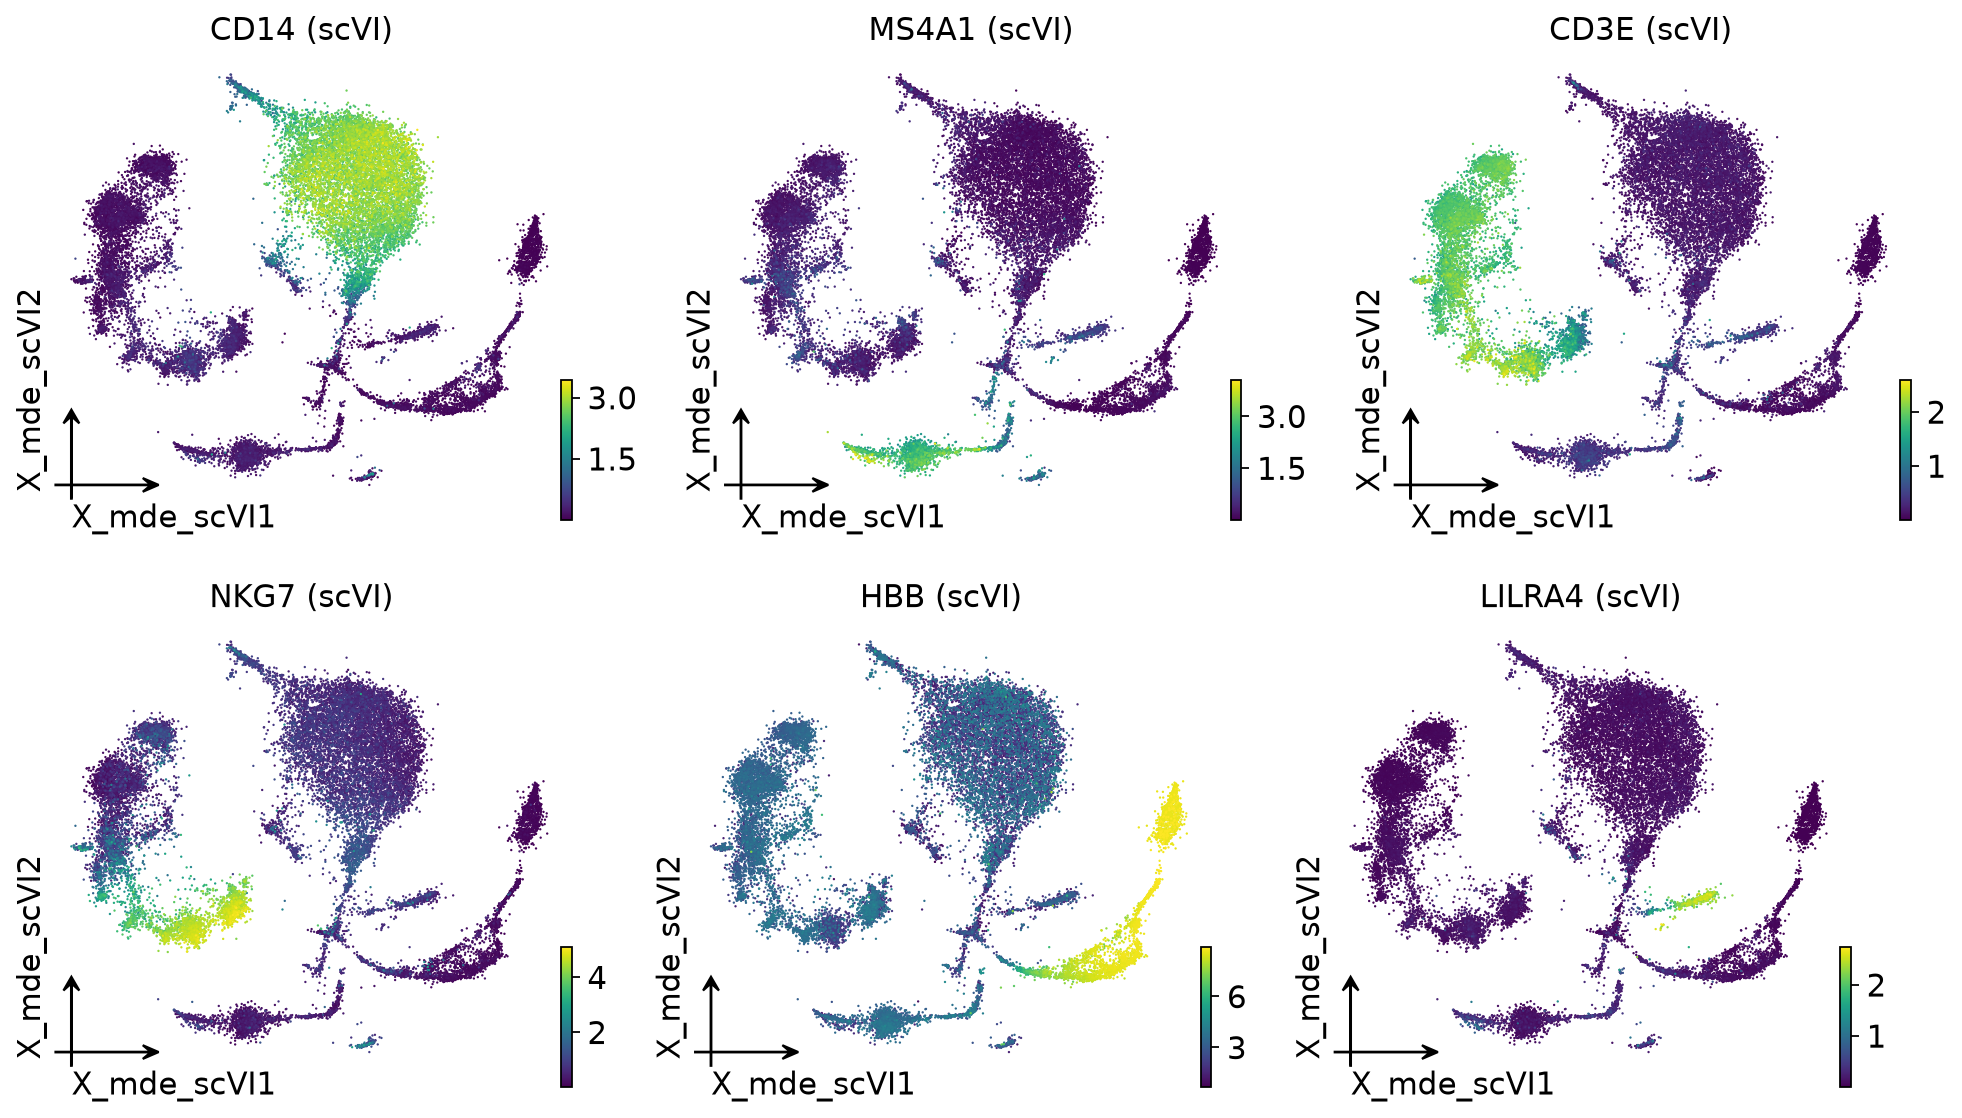

In [14]:
ov.pl.embedding(adata, basis='X_mde_scVI', color=[f'{g} (scVI)' for g in markers],
                frameon='small', ncols=3, cmap='viridis')

## 3. The same model trained from disk (AnnDataOOM)

`ov.read(path, storage='disk')` in CPU or CPU-GPU-mixed mode returns an
**AnnDataOOM**: `obs` / `var` are in memory, the matrix stays in the `.h5ad`.
`ov.pp.qc` and `ov.pp.preprocess` run on it chunk by chunk; the raw counts
remain a lazy reference to the file (`layers['counts']`).

`ov.vi.SCVI` streams the training genes of row blocks from the file with the
`pread`-based reader of anndataoom-fast (no HDF5 library calls on the data
path), shuffles blocks through a bounded buffer and sends them to the GPU — the
host never holds the matrix.

In [15]:
ov.settings.cpu_gpu_mixed_init()
adata_disk = ov.read(h5ad_path, storage='disk')
adata_disk

CPU-GPU mixed mode activated
Available GPU accelerators: CUDA


📂 Reading with anndata-rs (Rust · out-of-memory)
   neurips2021_bmmc_counts.h5ad  (298.4 MB)
   ✓ Loaded in 0.20s

💡 Data stays on disk. Use ov.pp.* for chunked processing.
   adata.close() when done · adata.to_adata() to materialise


name,dtype,preview
GEX_n_genes_by_counts,int32,"2796, 1542, 1959, … (3495)"
GEX_pct_counts_mt,float32,"8.509397, 6.381192, 8.657622, … (26303)"
GEX_size_factors,float64,"1.9806002765939965, 0.8578082381041044, 1.172110155842734, … (27423)"
GEX_phase,category,"G2M, S, G1"
ADT_n_antibodies_by_counts,int32,"127, 121, 108, … (80)"
ADT_total_counts,float32,"4431.0, 4030.0, 2954.0, … (6196)"
ADT_iso_count,float64,"14.0, 5.0, 22.0, … (64)"
cell_type,category,"CD14+ Mono, CD8+ T naive, NK, … (32)"
batch,category,"s1d3, s2d1, s3d7"
ADT_pseudotime_order,float32,"nan, 0.9845585, 0.9824424, … (4444)"


In [16]:
adata_disk = ov.pp.qc(adata_disk, tresh={'mito_perc': 0.2, 'nUMIs': 500, 'detected_genes': 250}, doublets=False)
adata_disk = ov.pp.preprocess(adata_disk, mode='shiftlog|pearson', n_HVGs=2000)
type(adata_disk.layers['counts'])

🖥️ Using CPU mode for QC (out-of-memory)...
   Auto-detected mitochondrial prefix: 'MT-'

📊 Step 1: Calculating QC Metrics

   ✓ Gene Family Detection:
   ┌──────────────────────────────┬────────────────────┬────────────────────┐
   │ Gene Family                  │ Genes Found        │ Detection Method   │
   ├──────────────────────────────┼────────────────────┼────────────────────┤
   │ Mitochondrial                │ 13                 │ Auto (MT-)         │
   ├──────────────────────────────┼────────────────────┼────────────────────┤
   │ Ribosomal                    │ 94                 │ Auto (RPS/RPL)     │
   ├──────────────────────────────┼────────────────────┼────────────────────┤
   │ Hemoglobin                   │ 11                 │ Auto (regex)       │
   └──────────────────────────────┴────────────────────┴────────────────────┘



   ✓ QC Metrics Summary:
   ┌─────────────────────────┬────────────────────┬─────────────────────────┐
   │ Metric                  │ Mean               │ Range (Min - Max)       │
   ├─────────────────────────┼────────────────────┼─────────────────────────┤
   │ nUMIs                   │ 5197               │ 742 - 32877             │
   ├─────────────────────────┼────────────────────┼─────────────────────────┤
   │ Detected Genes          │ 1339               │ 103 - 5543              │
   ├─────────────────────────┼────────────────────┼─────────────────────────┤
   │ Mitochondrial %         │ 6.6%               │ 0.0% - 23.0%            │
   ├─────────────────────────┼────────────────────┼─────────────────────────┤
   │ Ribosomal %             │ 24.6%              │ 0.1% - 69.4%            │
   ├─────────────────────────┼────────────────────┼─────────────────────────┤
   │ Hemoglobin %            │ 9.7%               │ 0.0% - 96.1%            │
   └─────────────────────────┴────────

   ✓ Final filtering: 0 cells, 0 genes removed

📊 Step 4: Doublet detection disabled
🔍 [2026-11-14 00:55:24] Running preprocessing in 'cpu-gpu-mixed' mode...
Begin robust gene identification
✅ Robust gene identification completed successfully.
Begin size normalization: shiftlog and HVGs selection pearson


    Time to analyze data (out-of-memory): 1.49 seconds.
✅ Preprocessing completed successfully.
    Added:
        'highly_variable_features', boolean vector (adata.var)
        'means', float vector (adata.var)
        'variances', float vector (adata.var)
        'residual_variances', float vector (adata.var)
        'counts', raw counts layer (adata.layers)
    End of size normalization: shiftlog and HVGs selection pearson


anndataoom._core._SubsetBackedArray

Same cells and the same 2 000 genes as in memory:

In [17]:
hvg_mem = adata.var_names[adata.var['highly_variable_features']]
hvg_disk = adata_disk.var_names[np.asarray(adata_disk.var['highly_variable_features'])]
print('same cells:', np.array_equal(adata.obs_names, adata_disk.obs_names),
      '| shared HVGs:', len(hvg_mem.intersection(hvg_disk)))

same cells: True | shared HVGs: 2000


In [18]:
model_disk = ov.vi.SCVI(adata_disk, layer='counts', batch_key='batch', genes='highly_variable_features',
                    n_layers=2, n_latent=30)
with ov.vi.MemoryMonitor() as mon_disk:
    model_disk.train(check_val_every_n_epoch=10)
mon_disk

Training:   0%|          | 0/296 [00:00<?, ?epoch/s]

MemoryMonitor(wall 77.1 s, RSS 6.55 -> peak 6.63 GB (+0.08), GPU used peak 2.48 GB)

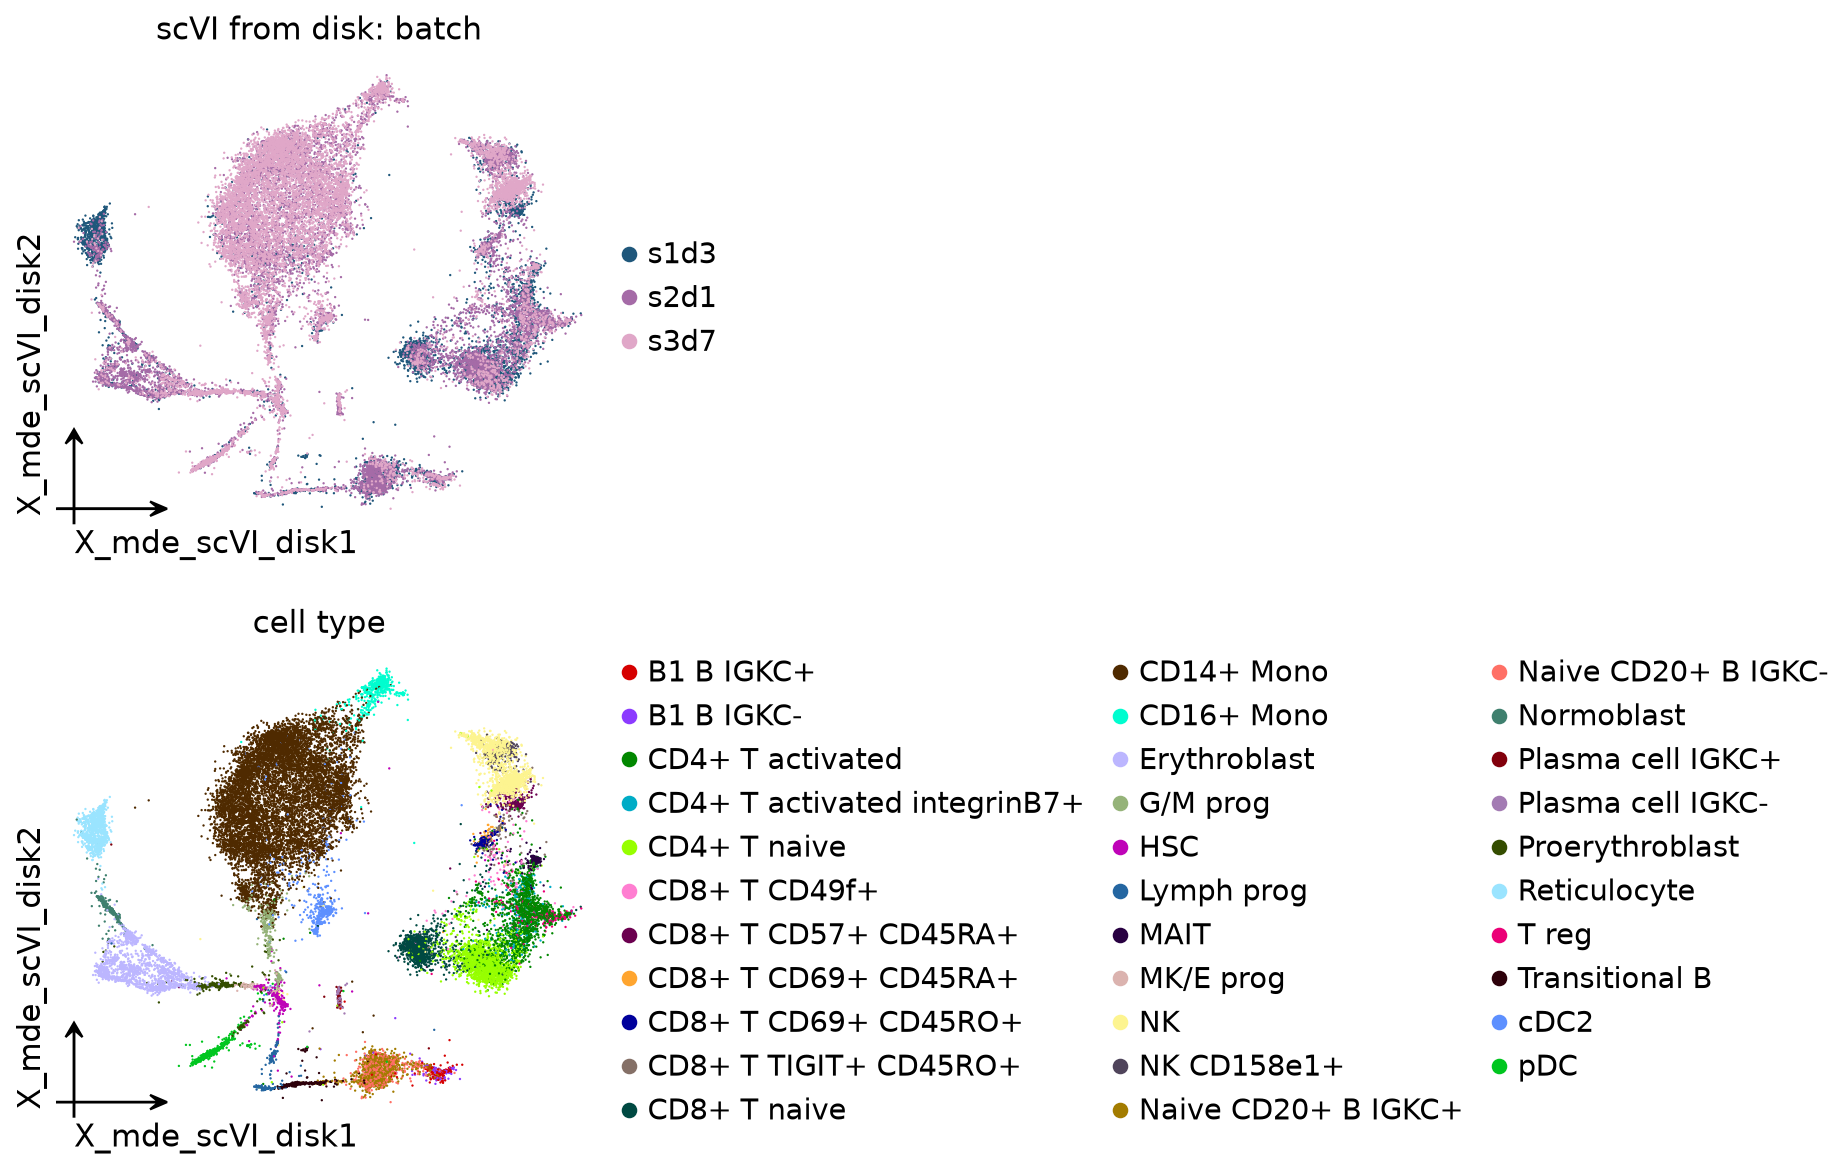

In [19]:
adata.obsm['X_scVI_disk'] = model_disk.get_latent_representation()
adata.obsm['X_mde_scVI_disk'] = ov.vi.mde(adata.obsm['X_scVI_disk'])
ov.pl.embedding(adata, basis='X_mde_scVI_disk', color=['batch', 'cell_type'],
                frameon='small', wspace=0.65, title=['scVI from disk: batch', 'cell type'])

## 4. GPU mode with Dask

In GPU mode `ov.read(path, storage='disk')` returns an AnnData whose `X` is a
Dask array of row blocks (`chunk_size` cells each). `ov.pp.qc` /
`ov.pp.preprocess` build lazy Dask graphs; `ov.vi` computes the blocks as cupy
arrays on the GPU and hands them to torch without a host copy.

> **Note.** `ov.settings.gpu_init()` additionally sets up RAPIDS
> (`rapids_singlecell`, `rmm`) for the in-memory GPU kernels. RAPIDS has no
> wheels for this cluster's glibc 2.17, so we only switch the mode with
> `ov.settings.mode = 'gpu'` — the Dask path of `ov.vi` needs nothing but
> `cupy` and `torch`. On a machine with RAPIDS use `ov.settings.gpu_init()`.

In [20]:
ov.settings.mode = 'gpu'
adata_gpu = ov.read(h5ad_path, storage='disk', chunk_size=5000)
adata_gpu.X

storage='disk' (GPU) reads X, obs, var and uns; skipped: obsm


dask.array<concatenate, shape=(27423, 13953), dtype=float32, chunksize=(5000, 13953), chunktype=cupyx.csr_matrix>

In [21]:
adata_gpu = ov.pp.qc(adata_gpu, tresh={'mito_perc': 0.2, 'nUMIs': 500, 'detected_genes': 250}, doublets=False)
adata_gpu = ov.pp.preprocess(adata_gpu, mode='shiftlog|pearson', n_HVGs=2000)

🚀 Using RAPIDS GPU to calculate QC...

🔍 Quality Control Analysis (GPU-Accelerated):
   Dataset shape: 27,423 cells × 13,953 genes
   QC mode: seurat
   Doublet detection: disabled
   Auto-detected mitochondrial prefix: 'MT-'
   Mitochondrial genes: MT-

📊 Step 1: Calculating QC Metrics

   ✓ Gene Family Detection:
   ┌──────────────────────────────┬────────────────────┬────────────────────┐
   │ Gene Family                  │ Genes Found        │ Detection Method   │
   ├──────────────────────────────┼────────────────────┼────────────────────┤
   │ Mitochondrial                │ 13                 │ Auto (MT-)         │
   ├──────────────────────────────┼────────────────────┼────────────────────┤
   │ Ribosomal                    │ 94                 │ Auto (RPS/RPL)     │
   ├──────────────────────────────┼────────────────────┼────────────────────┤
   │ Hemoglobin                   │ 11                 │ Auto (regex)       │
   └──────────────────────────────┴────────────────────┴───


   ✓ QC Metrics Summary:
   ┌─────────────────────────┬────────────────────┬─────────────────────────┐
   │ Metric                  │ Mean               │ Range (Min - Max)       │
   ├─────────────────────────┼────────────────────┼─────────────────────────┤
   │ nUMIs                   │ 5197               │ 742 - 32877             │
   ├─────────────────────────┼────────────────────┼─────────────────────────┤
   │ Detected Genes          │ 1339               │ 103 - 5543              │
   ├─────────────────────────┼────────────────────┼─────────────────────────┤
   │ Mitochondrial %         │ 6.6%               │ 0.0% - 23.0%            │
   ├─────────────────────────┼────────────────────┼─────────────────────────┤
   │ Ribosomal %             │ 24.6%              │ 0.1% - 69.4%            │
   ├─────────────────────────┼────────────────────┼─────────────────────────┤
   │ Hemoglobin %            │ 9.7%               │ 0.0% - 96.1%            │
   └─────────────────────────┴────────

✅ Robust gene identification completed successfully.
Begin size normalization: shiftlog and HVGs selection pearson
    Time to analyze data (dask): 0.14 seconds.
✅ Preprocessing completed successfully.
    Added:
        'highly_variable_features', boolean vector (adata.var)
        'means', float vector (adata.var)
        'variances', float vector (adata.var)
        'residual_variances', float vector (adata.var)
        'counts', raw counts layer (adata.layers)
    End of size normalization: shiftlog and HVGs selection pearson

╭─ SUMMARY: preprocess ──────────────────────────────────────────────╮
│  Duration: 0.2004s                                                 │
│  Shape:    26,997 x 13,953 (Unchanged)                             │
│                                                                    │
│  CHANGES DETECTED                                                  │
│  ────────────────                                                  │
│  ● VAR    │ ✚ highly_variable (bool

In [22]:
model_gpu = ov.vi.SCVI(adata_gpu, layer='counts', batch_key='batch', genes='highly_variable_features',
                    n_layers=2, n_latent=30)
with ov.vi.MemoryMonitor() as mon_gpu:
    model_gpu.train(check_val_every_n_epoch=10)
mon_gpu

Training:   0%|          | 0/296 [00:00<?, ?epoch/s]

MemoryMonitor(wall 109.0 s, RSS 7.14 -> peak 7.51 GB (+0.37), GPU used peak 3.30 GB)

In [23]:
adata.obsm['X_scVI_dask'] = model_gpu.get_latent_representation()
ov.settings.cpu_init()   # back to the default mode

CPU mode activated


### Memory and time of the three runs

`rss_growth_gb` is how much the process's resident memory grew during
`train()`; `epoch_s` the median epoch time.

In [24]:
runs = {'in memory': (model, mon_mem), 'disk (AnnDataOOM)': (model_disk, mon_disk),
        'GPU mode (Dask)': (model_gpu, mon_gpu)}
pd.DataFrame({k: {**mon.summary(), 'epochs': len(m.history_['time']),
                  'epoch_s': np.median(m.history_['time']),
                  'final elbo_validation': m.history_['elbo_validation'][-1]}
              for k, (m, mon) in runs.items()}).T.round(3)

                    wall_s  rss_start_gb  rss_peak_gb  rss_growth_gb  \
in memory           53.226         2.169        2.975          0.806   
disk (AnnDataOOM)   77.058         6.550        6.629          0.078   
GPU mode (Dask)    109.001         7.139        7.513          0.374   

                   gpu_peak_gb  epochs  epoch_s  final elbo_validation  
in memory                1.385   296.0    0.172               1264.672  
disk (AnnDataOOM)        2.479   296.0    0.249               1266.044  
GPU mode (Dask)          3.303   296.0    0.346               1265.136  

All three train the same model to the same validation ELBO (≈1265). The
`rss_start_gb` column differs because this process still holds the in-memory
AnnData of section 2 (with its dense scaled layer) when the disk runs start;
what matters is `rss_growth_gb`, the memory `train()` itself adds:

- **in memory**: +0.8 GB — the CSR matrix and its staging copies for the
  upload to the GPU;
- **disk (AnnDataOOM)**: < 0.1 GB — only the block-shuffle buffer and the
  minibatch staging arrays; the matrix is never loaded;
- **GPU mode (Dask)**: ≈ 0.4 GB — Dask graph and host-side block metadata; the
  blocks themselves live on the GPU.

Streaming costs some speed on a dataset this small (0.25 s and 0.35 s per epoch
vs. 0.17 s with the matrix resident on the GPU) and is what makes atlases that
do not fit in memory trainable at all: in the ov.vi benchmarks the full SEA-AD
atlas (1 378 211 cells, 91 GB `.h5ad`) trained from disk on the same H100 at
≈19 s per epoch with a peak RSS of 2.9 GB (AnnDataOOM, +0.8 GB during
training) and ≈21.5 s per epoch with 2.5 GB (Dask, +0.4 GB).

### Is the latent as good?

scib-style scores of the three latents (and PCA as the uncorrected reference),
computed with `ov.vi.integration_metrics` (scib-metrics; all in [0, 1], higher
is better). Training is stochastic, so the three scVI runs differ in the
second decimal, as different seeds would.

In [25]:
scores = ov.vi.integration_metrics(adata, ['X_pca', 'X_scVI', 'X_scVI_disk', 'X_scVI_dask'],
                                   batch_key='batch', label_key='cell_type', n_jobs=20)
scores.round(3)

INFO     NK CD158e1+ consists of a single batch or is too small. Skip.                                             


INFO     NK CD158e1+ consists of a single batch or is too small. Skip.                                             


INFO     NK CD158e1+ consists of a single batch or is too small. Skip.                                             


INFO     NK CD158e1+ consists of a single batch or is too small. Skip.                                             


             iLISI   kBET  ASW_batch  cLISI  ASW_label    NMI    ARI  \
embedding                                                              
X_pca        0.002  0.128      0.585  1.000      0.590  0.757  0.581   
X_scVI       0.371  0.528      0.858  0.999      0.555  0.813  0.793   
X_scVI_disk  0.369  0.513      0.856  0.999      0.551  0.813  0.814   
X_scVI_dask  0.374  0.513      0.858  0.999      0.552  0.804  0.688   

             graph_conn  
embedding                
X_pca             0.843  
X_scVI            0.868  
X_scVI_disk       0.863  
X_scVI_dask       0.857  

## 5. SCANVI: transfer labels to a new donor

We hide all labels of donor `s1d3` (5 935 cells) and ask SCANVI to annotate it
from the other two donors. `SCANVI.from_scvi_model` starts from the trained
in-memory scVI weights; following scvi-tools it then trains only a few epochs
(10 here) with the classifier.

In [26]:
query = (adata.obs['batch'] == 's1d3').values
labels = adata.obs['cell_type'].astype(str).where(~query, 'Unknown')
adata.obs['label_hidden'] = pd.Categorical(labels)
adata.obs['label_hidden'].value_counts().head()

label_hidden
CD14+ Mono      9014
Unknown         5933
NK              1524
Erythroblast    1508
CD4+ T naive    1102
Name: count, dtype: int64

In [27]:
scanvi = ov.vi.SCANVI.from_scvi_model(model, unlabeled_category='Unknown',
                                      labels_key='label_hidden')
scanvi.train()

Training:   0%|          | 0/10 [00:00<?, ?epoch/s]

SCANVI(n_obs=26997, n_vars=2000, n_batch=3, n_labels=32, layer='counts', trained=True)

In [28]:
adata.obs['scANVI_pred'] = pd.Categorical(scanvi.predict(),
                                          categories=adata.obs['cell_type'].cat.categories)
truth = adata.obs['cell_type'].astype(str).values
correct = adata.obs['scANVI_pred'].astype(str).values == truth
print(f'accuracy on the held-out donor s1d3: {correct[query].mean():.3f} ({query.sum()} cells)')

accuracy on the held-out donor s1d3: 0.838 (5933 cells)


Accuracy per cell type of the held-out donor (15 most frequent types):

In [29]:
per_type = pd.DataFrame({'cell_type': truth[query], 'correct': correct[query]})
per_type.groupby('cell_type')['correct'].agg(['mean', 'size']).sort_values('size', ascending=False).head(15).round(3)

                               mean  size
cell_type                                
Reticulocyte                  0.987   929
CD8+ T naive                  0.942   878
CD4+ T naive                  0.929   833
CD4+ T activated              0.841   547
CD14+ Mono                    0.987   309
NK                            0.535   271
Naive CD20+ B IGKC+           0.947   265
CD8+ T CD57+ CD45RA+          0.315   251
Transitional B                0.924   249
Erythroblast                  1.000   228
Naive CD20+ B IGKC-           0.766   171
CD4+ T activated integrinB7+  0.021   141
Normoblast                    0.806   129
MAIT                          0.936   109
Lymph prog                    0.920    87

Abundant types shared by all donors transfer well (reticulocytes, CD14⁺
monocytes, erythroblasts ≥ 0.98; naive CD4⁺ / CD8⁺ T, naive and transitional B
cells ≥ 0.92). The errors are informative rather than random:

- **CD8⁺ T CD57⁺ CD45RA⁺** (0.32) and **CD4⁺ T activated integrinB7⁺** (0.02)
  are almost private to `s1d3` (only 30 and a handful of reference cells in the
  other donors), so the classifier has little to learn them from and assigns
  the neighbouring CD8⁺ memory / activated CD4⁺ states.
- About half of the `s1d3` **NK** cells are called **NK CD158e1⁺**, a subtype
  annotated only in donor `s2d1` — a plausible call for KIR⁺ NK cells, which
  the authors did not split out in `s1d3`.

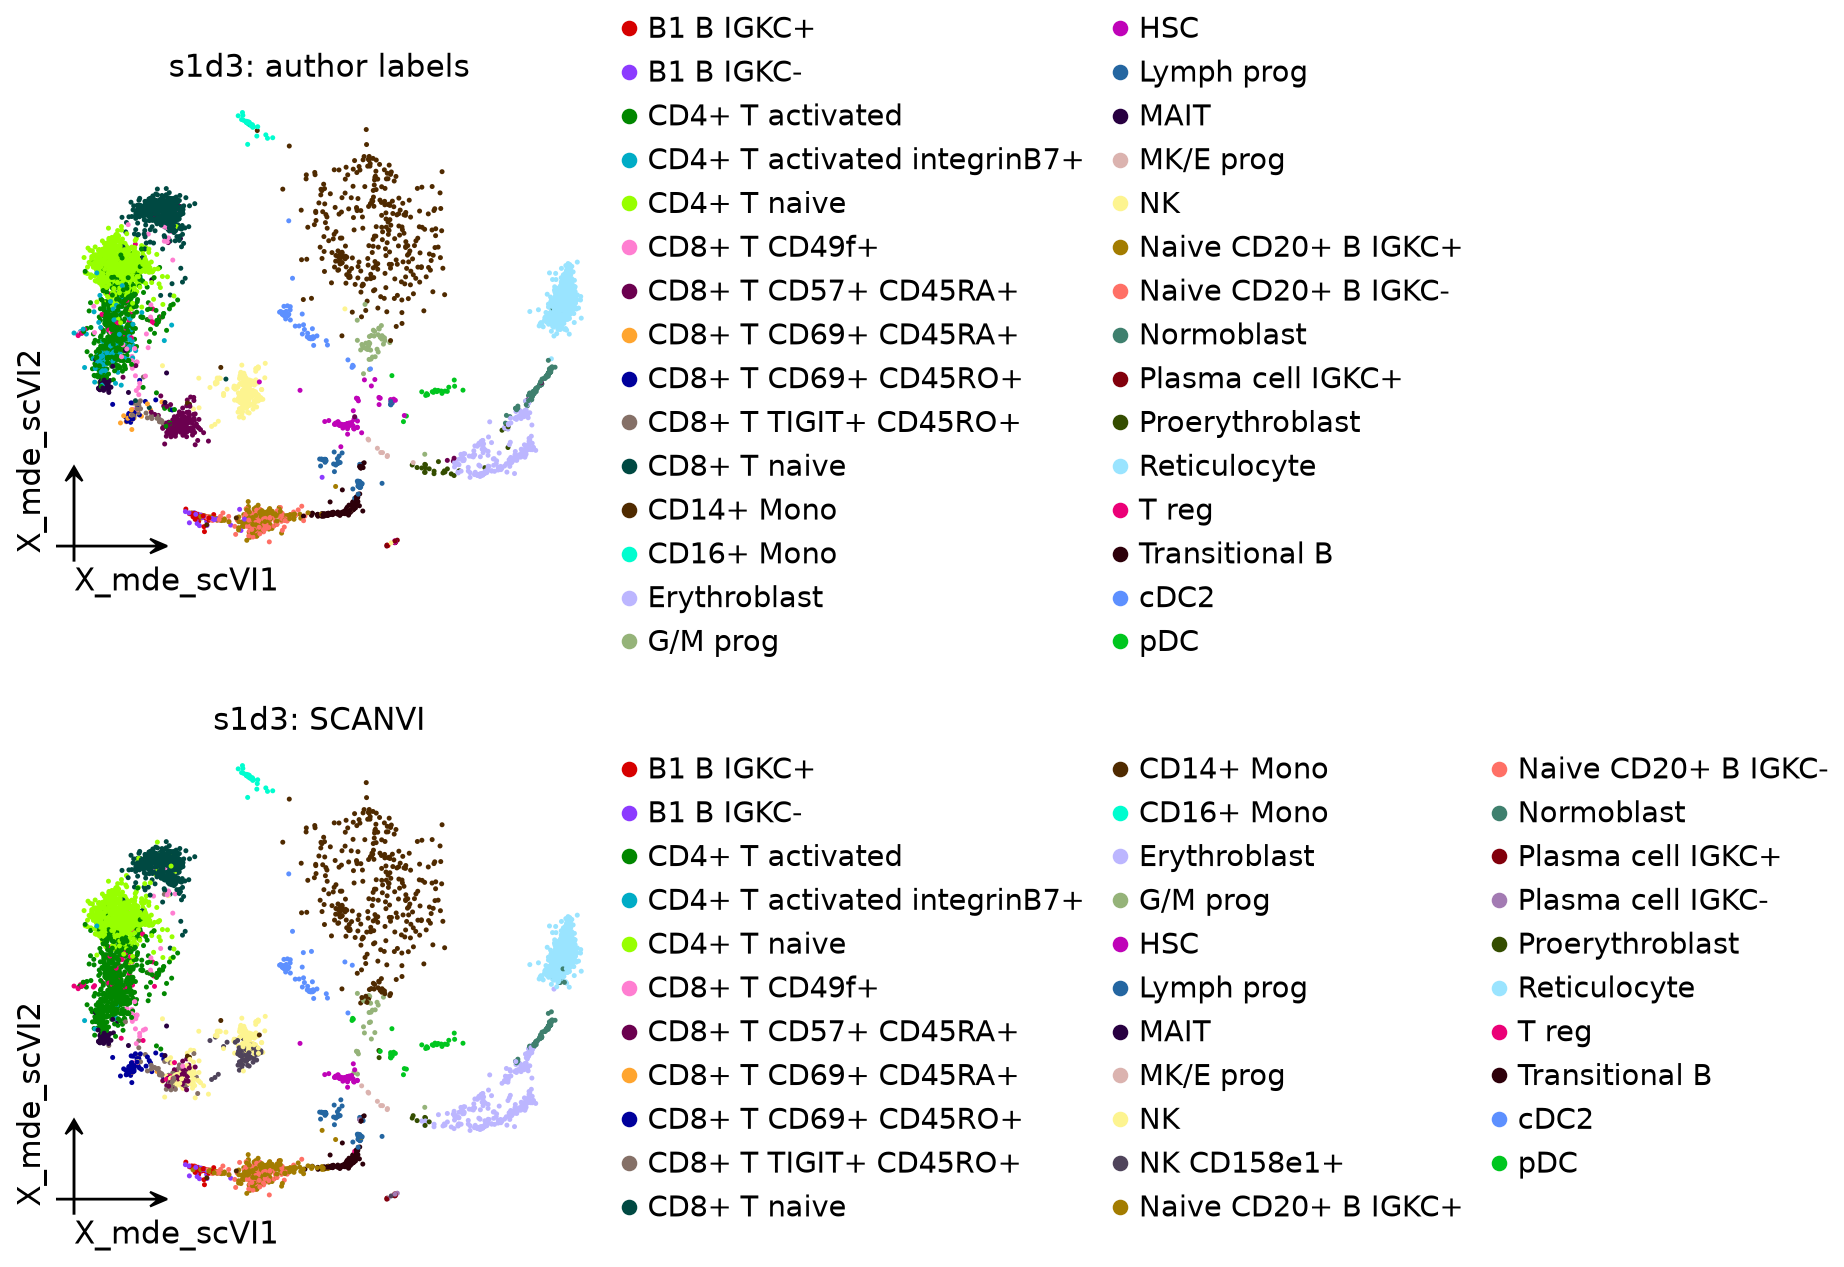

In [30]:
adata.uns['scANVI_pred_colors'] = adata.uns['cell_type_colors']
ov.pl.embedding(adata[query], basis='X_mde_scVI', color=['cell_type', 'scANVI_pred'],
                frameon='small', wspace=0.65, title=['s1d3: author labels', 's1d3: SCANVI'])

SCANVI also returns class probabilities (`scanvi.predict(soft=True)`) and its own
latent (`scanvi.get_latent_representation()`); it trains on disk-backed and
Dask data exactly like SCVI.

## 6. Multi-GPU training

`train(devices=[...])` starts one process per GPU (PyTorch DDP, NCCL) from the
notebook. Each process reads its own share of row blocks: for an AnnDataOOM the
parent resolves the file layout once and the workers read with `pread`, never
opening the file through HDF5 — so there is no HDF5 file lock to contend for and
any number of readers can share one `.h5ad` (an `h5py` reader fails with
`BlockingIOError` when a writer holds the file; the `pread` reader does not).
In-memory data is shared through shared memory; Dask data is computed by each
rank on its own GPU. The effective batch size is `batch_size × n_GPUs`.

This notebook ran on a single GPU, so the cell below is not executed:

```python
adata = ov.read('atlas.h5ad', storage='disk')               # AnnDataOOM
model = ov.vi.SCVI(adata, layer='counts', batch_key='donor',
                   genes='highly_variable_features')
model.train(devices=[0, 1, 2, 3])                            # 4 GPUs, one process each
adata.obsm['X_scVI'] = model.get_latent_representation()
```

`devices='cpu:8'` does the same with 8 CPU processes (gloo). Scripts can
also be launched with `torchrun` — `model.train()` detects the launch, rank 0
broadcasts the file layout, and the weights end identical on all ranks:

```bash
torchrun --nproc_per_node=4 train_scvi.py
```

## 7. Speed vs. scvi-tools

From the ov.vi benchmarks (`benchmarks/vi/results.md` in the omicverse
repository): same hyper-parameters (scvi-tools defaults), same epochs, wall
time of `train()`; one NVIDIA H100 80 GB, 16 CPU threads, scvi-tools 1.5.2.
Integration scores (iLISI, kBET, ASW, NMI / ARI) and ELBOs of the two
implementations agree within seed-to-seed variation.

| Model / data | Epochs | ov.vi (s) | scvi-tools (s) | Speed-up |
|---|---|---|---|---|
| SCVI, SEA-AD 5k cells | 50 | 2.3 | 10.9 | 4.7× |
| SCVI, SEA-AD 5k cells | 400 | 14.7 | 85.8 | 5.8× |
| SCVI, SEA-AD 50k cells | 160 | 52.3 | 337.4 | 6.5× |
| SCVI, SEA-AD 300k cells | 5 | 10.4 | 64.4 | 6.2× |
| SCANVI, SEA-AD 5k (70 % labels hidden) | 400 | 37.9 | 173.6 | 4.6× |
| TOTALVI, 10x PBMC 5k + 10k CITE-seq | 400 | 43.2 (CUDA graph) / 109.6 | 189.2 | 4.4× / 1.7× |

Full SEA-AD (1 378 211 cells × 2 000 HVGs, 91 GB `.h5ad`) trained from disk
with ov.vi: ≈18–22 s per epoch, peak host RSS 2.5–2.9 GB (scvi-tools needs the
matrix in memory).

## Summary

- `ov.vi.SCVI / SCANVI / TOTALVI` follow the scvi-tools API, take their
  configuration in the constructor and train on in-memory, disk-backed
  (AnnDataOOM) and Dask-backed data with the same code.
- On the NeurIPS 2021 bone-marrow data the three backends give equivalent
  latents (iLISI 0.37, kBET 0.51–0.53, NMI 0.80–0.81 vs. 0.002 / 0.13 / 0.76
  for PCA); disk training adds < 0.1 GB of host memory.
- SCANVI transfers the annotation to an unseen donor with 84 % accuracy
  across 32 fine-grained types after 10 epochs on top of the scVI model; the
  misses are donor-specific or graded states.
- `ov.single.batch_correction(methods='scVI' | 'scANVI' | 'totalVI')` runs the
  same models — see the [zoo](zoo/index.md).